# LAB #3 MAchine Learning Lab 3

## Name: Muhammad Qasim

### CMD ID: 023-24-0279


In [2]:
#Task 1
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

# Define the path to the cleaned dataset
cleaned_data_filename = 'clean_churn.csv'

# Load the cleaned dataset
print(f"Loading '{cleaned_data_filename}'...")
df_churn = pd.read_csv(cleaned_data_filename)
print("Data loaded successfully into `df_churn`.")

# Verify its shape
print("\n--- Dataset Shape ---")
print(df_churn.shape)

# Verify column dtypes
print("\n--- Column Data Types ---")
# Using .info() for a concise summary including non-null counts and dtypes
df_churn.info()

# Verify no missing values remaining
print("\n--- Missing Values Check ---")
missing_values_series = df_churn.isnull().sum()
missing_values_count = missing_values_series.sum()
if missing_values_count == 0:
    print("No missing values found in the dataset.")
else:
    print(f"WARNING: {missing_values_count} missing values found across the following columns:\n{missing_values_series[missing_values_series > 0]}")


Loading 'clean_churn.csv'...
Data loaded successfully into `df_churn`.

--- Dataset Shape ---
(7043, 20)

--- Column Data Types ---
<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   gender            7043 non-null   str    
 1   SeniorCitizen     7043 non-null   int64  
 2   Partner           7043 non-null   str    
 3   Dependents        7043 non-null   str    
 4   tenure            7043 non-null   int64  
 5   PhoneService      7043 non-null   str    
 6   MultipleLines     7043 non-null   str    
 7   InternetService   7043 non-null   str    
 8   OnlineSecurity    7043 non-null   str    
 9   OnlineBackup      7043 non-null   str    
 10  DeviceProtection  7043 non-null   str    
 11  TechSupport       7043 non-null   str    
 12  StreamingTV       7043 non-null   str    
 13  StreamingMovies   7043 non-null   str    
 14  Contract       

Task 2:

**In 1–2 sentences, restate the ML problem: what exactly are you predicting, and why does it matter to the
business?**

**Answer**:


3. Define y as the Churn column, encoded as 0/1. Define X as the remaining relevant columns — drop any
identifier column still present.
4. Convert every remaining categorical column in X into numeric form. Briefly justify your choice of encoding
method (e.g. one-hot vs. manual mapping).
5. Confirm X contains only numeric columns and has no missing values before moving on.

In [3]:
#Task 3
y = df_churn["Churn"].map({"Yes": 1, "No": 0})
x = df_churn.drop("Churn", axis=1)
#printing
x
y


0       0
1       0
2       1
3       0
4       1
       ..
7038    0
7039    0
7040    0
7041    1
7042    0
Name: Churn, Length: 7043, dtype: int64

In [4]:
#Task 4
categorical_cols = x.select_dtypes(include=["object"]).columns.tolist()
#printing
categorical_cols

x_encoded = pd.get_dummies(x,columns = categorical_cols)
#printing
x_encoded

C:\Users\UserX\AppData\Local\Temp\ipykernel_19924\1374536060.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = x.select_dtypes(include=["object"]).columns.tolist()


,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,gender_Female,gender_Male,Partner_No,Partner_Yes,Dependents_No,Dependents_Yes,...,StreamingMovies_Yes,Contract_Month-to-month,Contract_One year,Contract_Two year,PaperlessBilling_No,PaperlessBilling_Yes,PaymentMethod_Bank transfer (automatic),PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,1,29.85,29.85,True,False,False,True,True,False,...,False,True,False,False,False,True,False,False,True,False
1,0,34,56.95,1889.50,False,True,True,False,True,False,...,False,False,True,False,True,False,False,False,False,True
2,0,2,53.85,108.15,False,True,True,False,True,False,...,False,True,False,False,False,True,False,False,False,True
3,0,45,42.30,1840.75,False,True,True,False,True,False,...,False,False,True,False,True,False,True,False,False,False
4,0,2,70.70,151.65,True,False,True,False,True,False,...,False,True,False,False,False,True,False,False,True,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7038,0,24,84.80,1990.50,False,True,False,True,False,True,...,True,False,True,False,False,True,False,False,False,True
7039,0,72,103.20,7362.90,True,False,False,True,False,True,...,True,False,True,False,False,True,False,True,False,False
7040,0,11,29.60,346.45,True,False,False,True,False,True,...,False,True,False,False,False,True,False,False,True,False
7041,1,4,74.40,306.60,False,True,False,True,True,False,...,False,True,False,False,False,True,False,False,False,True


In [ ]:
#Task 5 Confirm X contains only numeric columns and has no missing values before moving on.
x_encoded.info()
#checking for missing values
missing_values_count = x_encoded.isnull().sum().sum()
if missing_values_count == 0:
    
    print("No missing values found in the dataset.")

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 45 columns):
 #   Column                                   Non-Null Count  Dtype  
---  ------                                   --------------  -----  
 0   SeniorCitizen                            7043 non-null   int64  
 1   tenure                                   7043 non-null   int64  
 2   MonthlyCharges                           7043 non-null   float64
 3   TotalCharges                             7043 non-null   float64
 4   gender_Female                            7043 non-null   bool   
 5   gender_Male                              7043 non-null   bool   
 6   Partner_No                               7043 non-null   bool   
 7   Partner_Yes                              7043 non-null   bool   
 8   Dependents_No                            7043 non-null   bool   
 9   Dependents_Yes                           7043 non-null   bool   
 10  PhoneService_No                          7043 non-null   bo

**PART 3**

**6. Split X and y into training and test sets (e.g. an 80/20 split). Why is** **stratify=y a sensible choice, given what you**
**found about the target's class balance in Lab 2?**

7 **Report the shape of X_train, X_test, y_train, and y_test**

In [6]:
#Task 6 Split X and y into training and test sets (e.g. an 80/20 split). Why is stratify=y a sensible choice, given what you found about the target's class balance in Lab 2?
X_train, X_test, y_train, y_test = train_test_split(x_encoded, y, test_size=0.2, random_state=42, stratify=y)

#shape
print("Shape of X_train:", X_train.shape)
print("Shape of X_test:", X_test.shape)
print("Shape of y_train:", y_train.shape)
print("Shape of y_test:", y_test.shape)



Shape of X_train: (5634, 45)
Shape of X_test: (1409, 45)
Shape of y_train: (5634,)
Shape of y_test: (1409,)


**PART 4**

**8. Train a DecisionTreeClassifier on the training data with default settings** **(only random_state fixed). Generate**
**predictions on both the training and test sets.**

**9. What depth did scikit-learn actually grow this tree to on its own? Does** **that surprise you?**

In [7]:
#Task 8
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

DecisionTreeClassifier_model = DecisionTreeClassifier(random_state=42)
DecisionTreeClassifier_model.fit(X_train, y_train)
DecisionTreeClassifier_train_predictions = DecisionTreeClassifier_model.predict(X_train)
DecisionTreeClassifier_test_predictions = DecisionTreeClassifier_model.predict(X_test)

#print
print("Training Accuracy:", accuracy_score(y_train, DecisionTreeClassifier_train_predictions))
print("Test Accuracy:", accuracy_score(y_test, DecisionTreeClassifier_test_predictions))

#Task 9
DecisionTreeClassifier_model.get_depth()


Training Accuracy: 0.9980475683351083
Test Accuracy: 0.7288857345635202


22

**PART 5**
**10.  Compute accuracy, precision, recall, and F1-score on the test set.**

**Report them in a small table.**

**11.  Plot the confusion matrix for the test set. How many actual churners did** **the model correctly catch, and how**
**many did it miss?**

**12. Given Lab 2's finding about class imbalance, which metric(s) do you trust** **most for this problem, and why?**

Evaluation Metrics on Test Set


,Metric,Score
0,Accuracy,0.728886
1,Precision,0.489637
2,Recall,0.505348
3,F1-Score,0.497368


Confusion Matrix:
[[838 197]
 [185 189]]


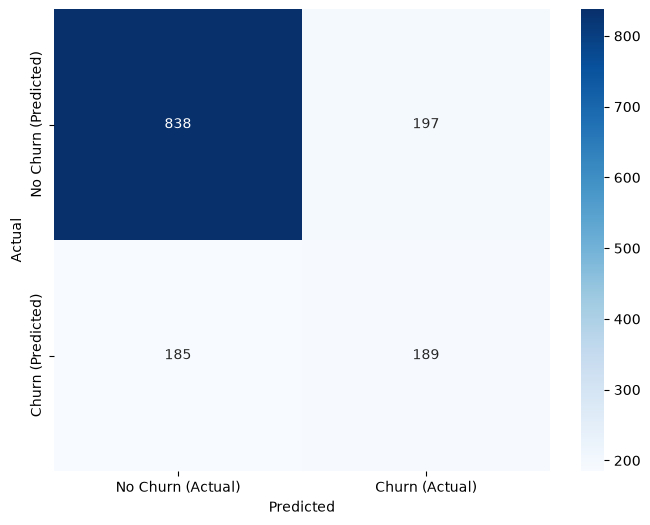

In [8]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
#Task 10
# Compute metrics on the test set
accuracy = accuracy_score(y_test, DecisionTreeClassifier_test_predictions)
precision = precision_score(y_test, DecisionTreeClassifier_test_predictions)
recall = recall_score(y_test, DecisionTreeClassifier_test_predictions)
f1 = f1_score(y_test, DecisionTreeClassifier_test_predictions)

# Report them in a small table
metrics_df = pd.DataFrame({
    'Metric': ['Accuracy', 'Precision', 'Recall', 'F1-Score'],
    'Score': [accuracy, precision, recall, f1]
})

print("Evaluation Metrics on Test Set")
display(metrics_df)


#Task 11
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# Compute the confusion matrix
conf_matrix = confusion_matrix(y_test, DecisionTreeClassifier_test_predictions)
print("Confusion Matrix:")
#plotting the confusion matrix
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=['No Churn (Actual)', 'Churn (Actual)'], yticklabels=['No Churn (Predicted)', 'Churn (Predicted)'])
plt.xlabel('Predicted')
plt.ylabel('Actual')

print(conf_matrix)


**Task 12**

**Given Lab 2's finding about class imbalance, which metric(s) do you trust** **most for this problem, and why?**

**ANS:**

**PART 6**

**13. Compare your baseline tree's accuracy on the training set vs. the test** **set. Is there a large gap? What does that**
**suggest about the model?**

**14. Train several Decision Trees at different max_depth values (e.g. 2, 3, 4,** **5, 6, 8, 10, and unrestricted). Record**
**train accuracy and test accuracy for each in a results table.**

**15. Plot train accuracy and test accuracy against max_depth on the same** **chart. At roughly what depth does the**
**model start to overfit? Explain how the chart shows this.**

In [9]:
#Task 13
accuracy_train = accuracy_score(y_train, DecisionTreeClassifier_train_predictions)
accuracy_test = accuracy_score(y_test, DecisionTreeClassifier_test_predictions)
print("Accuracy on Training Set (default tree):", accuracy_train)
print("Accuracy on Test Set (default tree):", accuracy_test)

#Task 14

results = []

max_depth_values = [2, 3, 4, 5, 6, 8, 10, None]

print("\nTraining Decision Trees with different max_depth values...")
for max_depth in max_depth_values:

    model = DecisionTreeClassifier(max_depth=max_depth, random_state=42)
    model.fit(X_train, y_train)


    train_predictions = model.predict(X_train)
    test_predictions = model.predict(X_test)


    accuracy_train = accuracy_score(y_train, train_predictions)
    accuracy_test = accuracy_score(y_test, test_predictions)


    results.append({
        'Max Depth': max_depth if max_depth is not None else 'Unrestricted',
        'Train Accuracy': accuracy_train,
        'Test Accuracy': accuracy_test})


results_df = pd.DataFrame(results)
print("\nDecision Tree Accuracy by Max Depth")
display(results_df)




Accuracy on Training Set (default tree): 0.9980475683351083
Accuracy on Test Set (default tree): 0.7288857345635202

Training Decision Trees with different max_depth values...

Decision Tree Accuracy by Max Depth


,Max Depth,Train Accuracy,Test Accuracy
0,2,0.765353,0.750887
1,3,0.791445,0.782115
2,4,0.796592,0.792051
3,5,0.803869,0.798439
4,6,0.810437,0.791341
5,8,0.837238,0.774308
6,10,0.878417,0.753726
7,Unrestricted,0.998048,0.728886


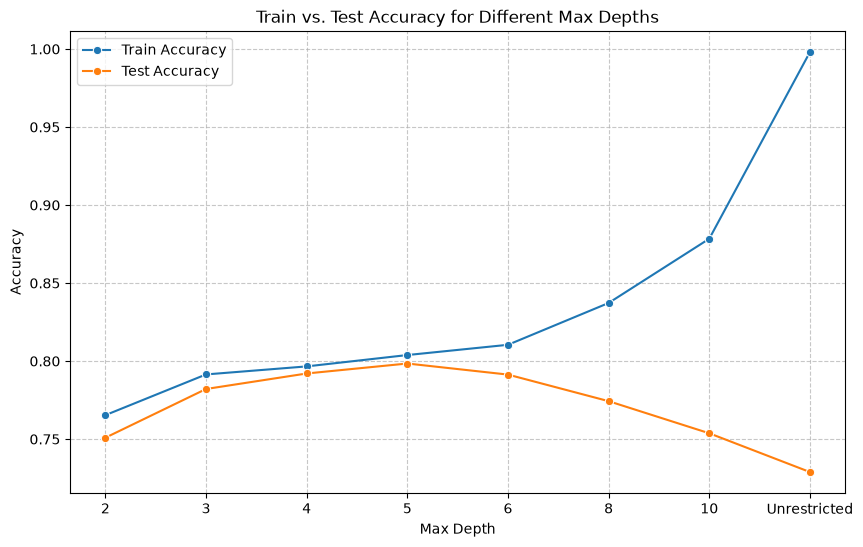

In [10]:
#Task 15

plt.figure(figsize=(10, 6))
sns.lineplot(x=results_df.index, y='Train Accuracy', data=results_df, marker='o', label='Train Accuracy')
sns.lineplot(x=results_df.index, y='Test Accuracy', data=results_df, marker='o', label='Test Accuracy')

plt.title('Train vs. Test Accuracy for Different Max Depths')
plt.xlabel('Max Depth') # Changed label as the actual values are shown in ticks
plt.ylabel('Accuracy')
plt.xticks(ticks=results_df.index, labels=results_df['Max Depth'])
plt.grid(True, linestyle='--', alpha=0.7)
plt.legend()
plt.show()


### Overfitting Analysis

Based on the plot, the model starts to show signs of overfitting roughly after a `max_depth` of 5 or 6.

**How the chart shows this:**

*   **Up to `max_depth` of 5-6:** Both train and test accuracies generally increase, or stay relatively close, indicating that the model is learning patterns effectively without memorizing the training data.
*   **Beyond `max_depth` of 5-6:** While the **Train Accuracy** continues to increase (approaching 100% at 'Unrestricted' depth), the **Test Accuracy** either plateaus or begins to decrease. This widening gap between training and test accuracy is a classic sign of overfitting. The model is becoming too complex, learning noise and specific examples from the training data, which hurts its ability to generalize to unseen test data.





16.   Based on your Part 6 table/plot, select a max_depth you consider the best model. Justify your choice in 2–3
sentences — it should not simply be the depth with the highest training accuracy.

17.    Retrain a Decision Tree at your chosen depth and report   its full evaluation metrics (as in Part 5) for comparison
        against the baseline.

18.   Retrain a Decision Tree with “entropy” as the splitting criterion rather than the default (“gini”) and report its
full evaluation metrics (as in Part 5) for comparison against the baseline.

19.    Extract and visualize feature_importances_ for your chosen model. Which 3–5 features matter most?


1.   In 2–3 sentences, connect the top features to what you already found in Lab 2's EDA — do they agree with the
patterns you saw then?











TASK 16

Q Based on your Part 6 table/plot, select a max_depth you consider the best model. Justify your choice in 2–3
sentences — it should not simply be the depth with the highest training accuracy.

ANS:

In [11]:
#Task 17
best_max_depth = 5
best_model = DecisionTreeClassifier(max_depth=best_max_depth, random_state=42)
best_model.fit(X_train, y_train)
best_train_predictions = best_model.predict(X_train)
best_test_predictions = best_model.predict(X_test)

best_accuracy_train = accuracy_score(y_train, best_train_predictions)
best_accuracy_test = accuracy_score(y_test, best_test_predictions)

print("Best Model (max_depth =", best_max_depth, ")")
print("Train Accuracy:", best_accuracy_train)
print("Test Accuracy:", best_accuracy_test)


Best Model (max_depth = 5 )
Train Accuracy: 0.80386936457224
Test Accuracy: 0.7984386089425124


In [12]:
#Task 18
Entropy_model = DecisionTreeClassifier(criterion='entropy', max_depth=best_max_depth,random_state=42)
Entropy_model.fit(X_train, y_train)
Entropy_train_predictions = Entropy_model.predict(X_train)
Entropy_test_predictions = Entropy_model.predict(X_test)

Entropy_accuracy_train = accuracy_score(y_train, Entropy_train_predictions)
Entropy_accuracy_test = accuracy_score(y_test, Entropy_test_predictions)

print("Entropy Model (max_depth =", best_max_depth, ")")
print("Train Accuracy:", Entropy_accuracy_train)
print("Test Accuracy:", Entropy_accuracy_test)


Entropy Model (max_depth = 5 )
Train Accuracy: 0.8033368832090877
Test Accuracy: 0.7970191625266146


In [13]:
#Task 19
# Extract and visualize feature_importances_ for your chosen model. Which 3–5 features matter most?
feature_importances = Entropy_model.feature_importances_
feature_names = X_train.columns
feature_importances_df = pd.DataFrame({'Feature': feature_names, 'Importance': feature_importances})
feature_importances_df = feature_importances_df.sort_values(by='Importance', ascending=False)

print("Feature Importances:")
display(feature_importances_df.head(10))

Feature Importances:


,Feature,Importance
36,Contract_Month-to-month,0.534037
1,tenure,0.136579
16,InternetService_Fiber optic,0.123031
2,MonthlyCharges,0.078134
3,TotalCharges,0.033432
37,Contract_One year,0.025932
43,PaymentMethod_Electronic check,0.024659
27,TechSupport_No,0.015970
18,OnlineSecurity_No,0.009664
21,OnlineBackup_No,0.008207


20. In 2–3 sentences, connect the top features to what you already found in Lab 2's EDA — do they agree with the
patterns you saw then?

Part 8

### Task 20

**Answer:**

Yes, the feature importance results generally agree with the patterns observed during the Lab 2 EDA. The strong importance of `Contract_Month-to-month` and `tenure` supports the earlier observation that customers with month-to-month contracts and shorter tenure are more likely to churn, while the importance of `InternetService_Fiber optic` and `MonthlyCharges` also reflects the differences in churn behavior seen across internet service types and customer charges.

### Task 21 — Conclusion

**Answer:**

In this lab, I built and evaluated Decision Tree classifiers to predict customer churn using the Telco Customer Churn dataset. The unrestricted baseline tree achieved very high training accuracy but much lower test accuracy, which showed clear overfitting. After testing different tree depths, I selected `max_depth = 5` because it achieved the best test accuracy of approximately **79.84%** while maintaining a much smaller training-test gap. The entropy-based model produced very similar performance but did not improve the results over the selected Gini model. The main limitations are the class imbalance and the fact that a single Decision Tree may not capture complex patterns as effectively as ensemble methods.

### Task 22 — Next Steps

**Answer:**

With more time, I would try a different classification algorithm such as Random Forest or Gradient Boosting to determine whether an ensemble model can improve generalization compared with a single Decision Tree. I would also investigate techniques for handling class imbalance and perform additional feature engineering to create more informative predictors. These changes could potentially improve recall and F1-score for churn customers while reducing the number of customers the model fails to identify.

In [14]:
# Task 23
# ID3 Decision Tree from Scratch - Play Badminton Dataset

import pandas as pd
import numpy as np

# Play Badminton dataset
data = {
    'Outlook': [
        'Sunny', 'Sunny', 'Overcast', 'Rain', 'Rain', 'Rain',
        'Overcast', 'Sunny', 'Sunny', 'Rain', 'Sunny', 'Overcast',
        'Overcast', 'Rain'
    ],
    'Temperature': [
        'Hot', 'Hot', 'Hot', 'Mild', 'Cool', 'Cool',
        'Cool', 'Mild', 'Cool', 'Mild', 'Mild', 'Mild',
        'Hot', 'Mild'
    ],
    'Humidity': [
        'High', 'High', 'High', 'High', 'Normal', 'Normal',
        'Normal', 'High', 'Normal', 'Normal', 'Normal', 'High',
        'Normal', 'High'
    ],
    'Wind': [
        'Weak', 'Strong', 'Weak', 'Weak', 'Weak', 'Strong',
        'Strong', 'Weak', 'Weak', 'Weak', 'Strong', 'Strong',
        'Weak', 'Strong'
    ],
    'Play': [
        'No', 'No', 'Yes', 'Yes', 'Yes', 'No',
        'Yes', 'No', 'Yes', 'Yes', 'Yes', 'Yes',
        'Yes', 'No'
    ]
}

df = pd.DataFrame(data)


# -----------------------------
# Entropy
# -----------------------------
def entropy(target):
    values, counts = np.unique(target, return_counts=True)

    probabilities = counts / counts.sum()

    return -np.sum(
        probabilities * np.log2(probabilities)
    )


# -----------------------------
# Information Gain
# -----------------------------
def information_gain(df, attribute, target='Play'):
    total_entropy = entropy(df[target])

    values, counts = np.unique(
        df[attribute],
        return_counts=True
    )

    weighted_entropy = 0

    for value, count in zip(values, counts):

        subset = df[df[attribute] == value]

        weighted_entropy += (
            count / len(df)
        ) * entropy(subset[target])

    gain = total_entropy - weighted_entropy

    return gain


# -----------------------------
# Find Best Attribute
# -----------------------------
def best_attribute(df, attributes, target='Play'):

    gains = {}

    for attribute in attributes:
        gains[attribute] = information_gain(
            df,
            attribute,
            target
        )

    print("\nInformation Gain:")

    for attribute, gain in gains.items():
        print(f"{attribute}: {gain:.4f}")

    best = max(gains, key=gains.get)

    print(f"\nBest Attribute: {best}")

    return best


# -----------------------------
# ID3 Algorithm
# -----------------------------
def id3(df, attributes, target='Play', depth=0):

    # If all target values are the same
    if len(df[target].unique()) == 1:
        return df[target].iloc[0]

    # If no attributes remain
    if len(attributes) == 0:
        return df[target].mode()[0]

    print("\n" + "=" * 50)
    print(f"Split at Depth {depth}")
    print("=" * 50)

    print("Dataset:")
    print(df)

    # Calculate information gain
    best = best_attribute(
        df,
        attributes,
        target
    )

    tree = {best: {}}

    remaining_attributes = [
        attribute
        for attribute in attributes
        if attribute != best
    ]

    # Create branches
    for value in df[best].unique():

        subset = df[df[best] == value]

        print(
            f"\nBranch: {best} = {value}"
        )

        if subset.empty:
            tree[best][value] = df[target].mode()[0]

        else:
            tree[best][value] = id3(
                subset,
                remaining_attributes,
                target,
                depth + 1
            )

    return tree


# -----------------------------
# Run ID3
# -----------------------------

attributes = [
    'Outlook',
    'Temperature',
    'Humidity',
    'Wind'
]

print("Play Badminton Dataset:")
print(df)

print("\nInitial Entropy:")
print(f"{entropy(df['Play']):.4f}")

decision_tree = id3(
    df,
    attributes
)

print("\nFinal ID3 Decision Tree:")
print(decision_tree)

Play Badminton Dataset:
     Outlook Temperature Humidity    Wind Play
0      Sunny         Hot     High    Weak   No
1      Sunny         Hot     High  Strong   No
2   Overcast         Hot     High    Weak  Yes
3       Rain        Mild     High    Weak  Yes
4       Rain        Cool   Normal    Weak  Yes
5       Rain        Cool   Normal  Strong   No
6   Overcast        Cool   Normal  Strong  Yes
7      Sunny        Mild     High    Weak   No
8      Sunny        Cool   Normal    Weak  Yes
9       Rain        Mild   Normal    Weak  Yes
10     Sunny        Mild   Normal  Strong  Yes
11  Overcast        Mild     High  Strong  Yes
12  Overcast         Hot   Normal    Weak  Yes
13      Rain        Mild     High  Strong   No

Initial Entropy:
0.9403

Split at Depth 0
Dataset:
     Outlook Temperature Humidity    Wind Play
0      Sunny         Hot     High    Weak   No
1      Sunny         Hot     High  Strong   No
2   Overcast         Hot     High    Weak  Yes
3       Rain        Mild     Hi

## Submission Checklist

- [x] 1. Problem Definition
- [x] 2. Dataset Verification
- [x] 3. Feature/Target Preparation
- [x] 4. Train/Test Split
- [x] 5. Baseline Decision Tree
- [x] 6. Model Evaluation
- [x] 7. Overfitting Experiment
- [x] 8. Model Comparison
- [x] 9. Feature Importance
- [x] 10. Interpretation
- [x] 11. Conclusion
- [x] ID3 implementation from scratch